# L7 – Language Models (with PyTorch)

A **language model** predicts the next word from the previous words, $P(w_t \mid w_1 \dots w_{t-1})$. Everything in this lecture, from n-grams up to GPT, is a different way of doing that.

**Plan for this notebook**
1. Get a dataset (WikiText-2) and turn it into word ids
2. Short explanation of each model, then build and train it in PyTorch: **RNN → CNN → Transformer (encoder-decoder) → GPT → BERT**
3. Use the real pre-trained **BERT, GPT-2 and T5**
4. Compare everything with **perplexity**

> Run this on a GPU if you can (Colab: Runtime → Change runtime type → GPU). On CPU every model still trains, just slower.

## Background: from counting to predicting
**n-gram models** estimate the probability by counting how often a word follows the last n-1 words. If a context was never seen they need **backoff** or **interpolation**; if an n-gram was never seen they need **smoothing**. They also need huge count tables and only see a short window.

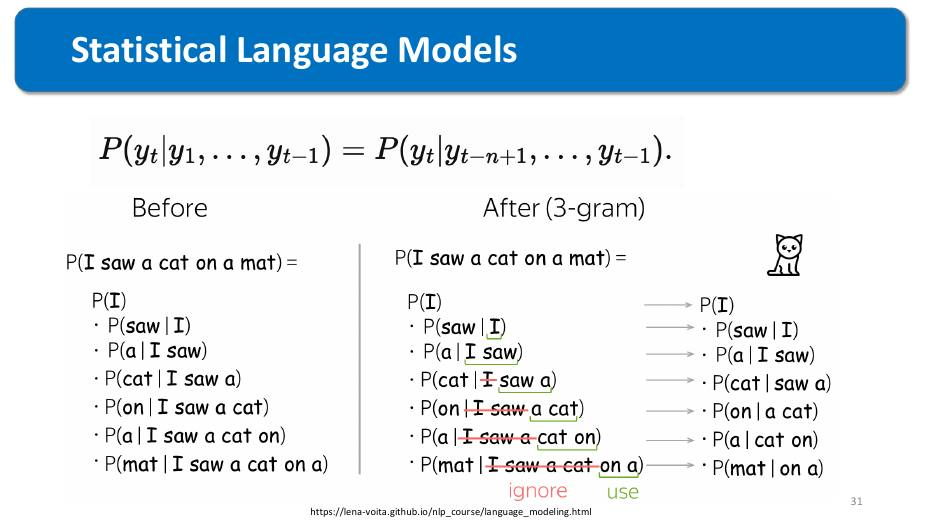
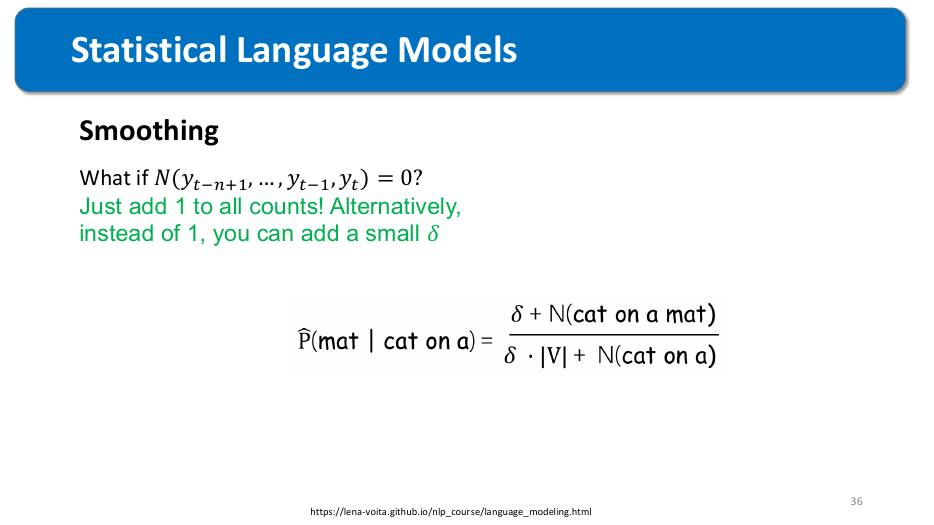

**Neural LMs** instead *predict* the probabilities: embed the context words → a network builds a context vector → a linear layer + softmax gives a probability for every word in the vocabulary. It's a classification problem with |V| classes, trained with **cross-entropy loss**.

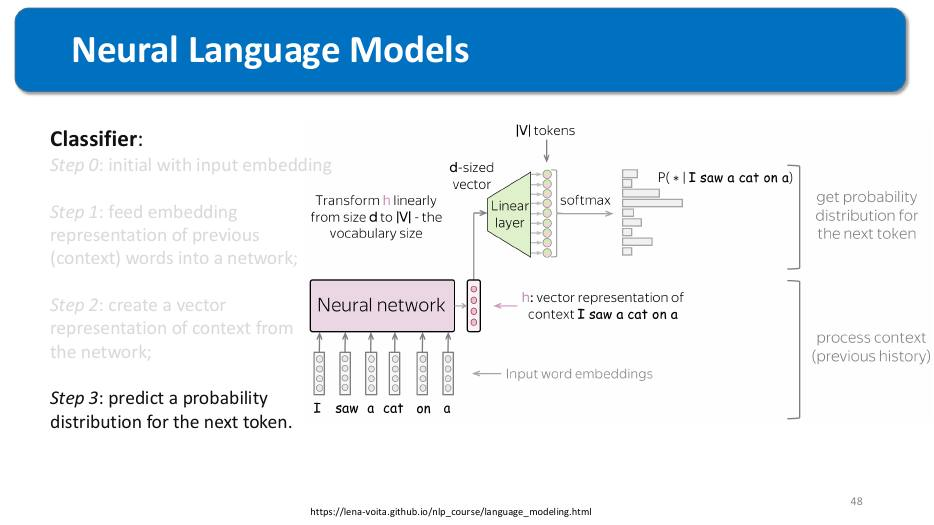

## 0. Setup and data

In [1]:
# !pip install torch datasets transformers sentencepiece nltk
import math, re, random
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
print("device:", device)

device: cpu


In [2]:
# WikiText-2: Wikipedia articles, a standard small LM dataset
try:
    from datasets import load_dataset
    ds = load_dataset("wikitext", "wikitext-2-raw-v1")
    train_text = " ".join(ds["train"]["text"])
    val_text = " ".join(ds["validation"]["text"])
except Exception as e:
    print("download failed, using a small built-in text instead ->", e)
    train_text = ("the cat sat on the mat . the dog sat on the rug . a cat is on a mat . "
                  "the patient has a nodule in the left lung . the nodule is small . ") * 300
    val_text = train_text[:5000]

print(train_text[:300])

/Users/deepanshu/Documents/NLP_6120/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


download failed, using a small built-in text instead -> Invalid HF URI 'hf://datasets/wikitext@b08601e04326c79dfdd32d625aee71d232d685c3/.huggingface.yaml'. Repository id must be 'namespace/name', got 'wikitext'.
the cat sat on the mat . the dog sat on the rug . a cat is on a mat . the patient has a nodule in the left lung . the nodule is small . the cat sat on the mat . the dog sat on the rug . a cat is on a mat . the patient has a nodule in the left lung . the nodule is small . the cat sat on the mat . the


In [3]:
def tokenize(text):
    # lowercase words + punctuation as separate tokens
    return re.findall(r"\w+|[^\w\s]", text.lower())

train_tokens = tokenize(train_text)[:300_000]   # keep it small so it trains fast
val_tokens = tokenize(val_text)[:30_000]

# vocabulary: the 5000 most common words + 2 special tokens
counts = Counter(train_tokens)
itos = ["<unk>", "<mask>"] + [w for w, _ in counts.most_common(5000)]
stoi = {w: i for i, w in enumerate(itos)}
V = len(itos)

def encode(tokens):
    return torch.tensor([stoi.get(t, 0) for t in tokens])

train_ids, val_ids = encode(train_tokens), encode(val_tokens)
print("vocab size:", V, "| train tokens:", len(train_ids), "| val tokens:", len(val_ids))
print(train_tokens[:12], "->", train_ids[:12].tolist())

vocab size: 19 | train tokens: 10800 | val tokens: 1325
['the', 'cat', 'sat', 'on', 'the', 'mat', '.', 'the', 'dog', 'sat', 'on', 'the'] -> [2, 6, 7, 4, 2, 8, 3, 2, 11, 7, 4, 2]


**Training examples:** cut the text into windows of 32 tokens. The input is the window and the target is the same window shifted by one word, so at **every position** the model learns to predict the next word.

In [4]:
SEQ_LEN = 32

def get_batch(ids, batch_size=32):
    starts = torch.randint(0, len(ids) - SEQ_LEN - 1, (batch_size,))
    x = torch.stack([ids[s : s + SEQ_LEN] for s in starts])
    y = torch.stack([ids[s + 1 : s + SEQ_LEN + 1] for s in starts])   # shifted by one
    return x.to(device), y.to(device)

x, y = get_batch(train_ids, batch_size=1)
print("input :", " ".join(itos[i] for i in x[0, :8].tolist()))
print("target:", " ".join(itos[i] for i in y[0, :8].tolist()))

input : in the left lung . the nodule is
target: the left lung . the nodule is small


**Shared helpers** used by every next-word model below:
- `train_lm`: minimize cross-entropy between the predicted distribution and the real next word
- `perplexity` = exp(average cross-entropy) on the validation set (lower is better; a model that guesses uniformly gets |V|)
- `generate`: repeatedly sample the next word and append it

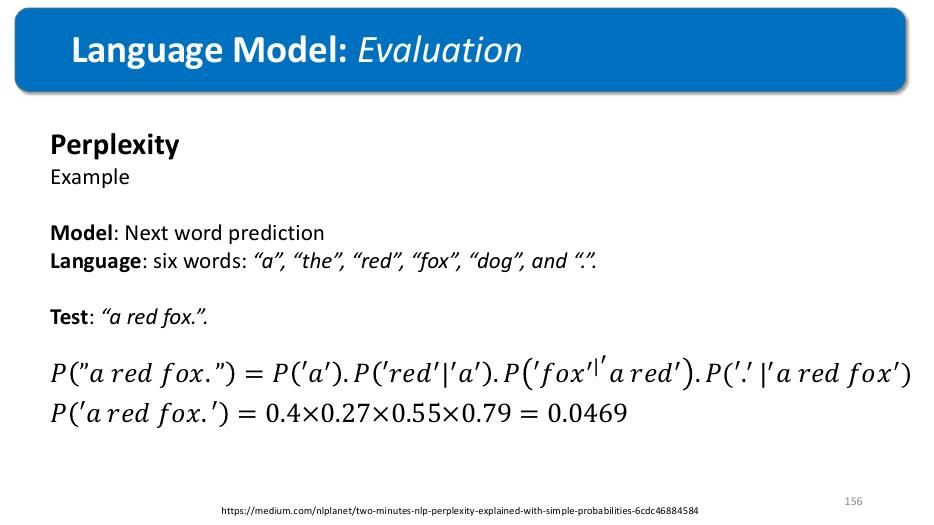

In [5]:
@torch.no_grad()
def perplexity(model, batches=20):
    model.eval()
    losses = []
    for _ in range(batches):
        x, y = get_batch(val_ids)
        logits = model(x)                                   # (batch, seq, V)
        losses.append(F.cross_entropy(logits.reshape(-1, V), y.reshape(-1)).item())
    model.train()
    return math.exp(sum(losses) / len(losses))

def train_lm(model, steps=1500, lr=3e-3):
    model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    for step in range(steps + 1):
        x, y = get_batch(train_ids)
        logits = model(x)
        loss = F.cross_entropy(logits.reshape(-1, V), y.reshape(-1))
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        if step % 300 == 0:
            print(f"step {step:5d} | train loss {loss.item():.2f} | val perplexity {perplexity(model):7.1f}")
    return model

@torch.no_grad()
def generate(model, prompt, n_words=15, temperature=0.8):
    model.eval()
    ids = encode(tokenize(prompt)).unsqueeze(0).to(device)
    for _ in range(n_words):
        logits = model(ids[:, -SEQ_LEN:])[:, -1] / temperature    # scores for the next word
        next_id = torch.multinomial(F.softmax(logits, dim=-1), 1)  # sample one
        ids = torch.cat([ids, next_id], dim=1)
    model.train()
    return " ".join(itos[i] for i in ids[0].tolist())

results = {}   # model name -> validation perplexity

## 1. RNN language model
An RNN reads the words one at a time and keeps a **hidden state** that summarizes everything so far; the same weights are reused at every step. We use an **LSTM** (an RNN that remembers longer).
- ✅ any input length, small model
- ❌ sequential, so slow; long context still fades

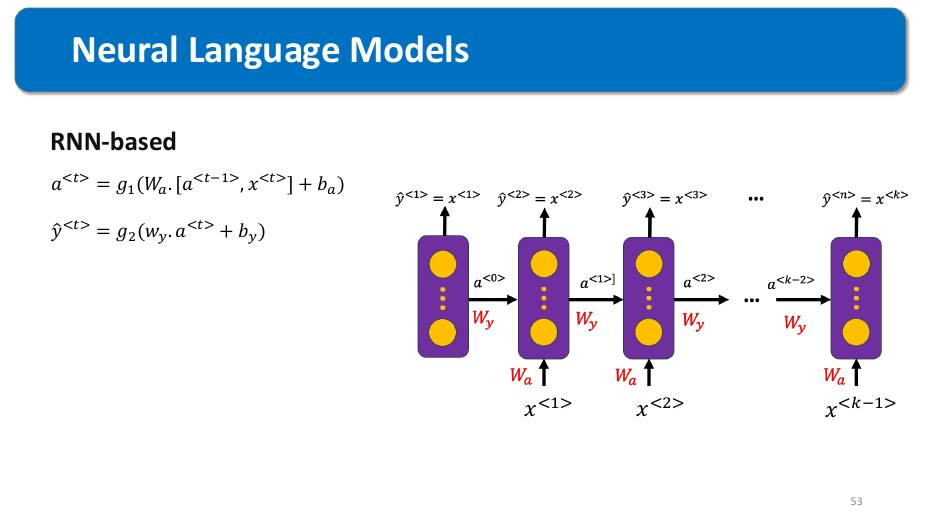

In [6]:
class RNNLM(nn.Module):
    def __init__(self, vocab_size, dim=256):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, dim)
        self.rnn = nn.LSTM(dim, dim, num_layers=2, batch_first=True, dropout=0.2)
        self.out = nn.Linear(dim, vocab_size)

    def forward(self, x):                 # x: (batch, seq)
        h, _ = self.rnn(self.embed(x))    # h: (batch, seq, dim), one hidden state per word
        return self.out(h)                # (batch, seq, vocab) scores for the next word

rnn = train_lm(RNNLM(V))
results["RNN (LSTM)"] = perplexity(rnn)
print(generate(rnn, "the history of the"))

step     0 | train loss 2.95 | val perplexity    16.2
step   300 | train loss 0.03 | val perplexity     1.0
step   600 | train loss 0.03 | val perplexity     1.0
step   900 | train loss 0.03 | val perplexity     1.0
step  1200 | train loss 0.03 | val perplexity     1.0
step  1500 | train loss 0.03 | val perplexity     1.0
the <unk> <unk> the dog sat on the rug . a cat is on a mat . the patient


## 2. CNN language model
A 1-D convolution slides a filter over the word embeddings to detect local patterns (phrases). **Kernel size** = how many words it looks at, **stride** = step size, **padding** = zeros on the sides.

For a language model:
- pad **only on the left**, so position t never sees future words (a *causal* convolution)
- **no pooling**, because we need an output at every position
- stack layers to see further back, with **residual connections** so the stack trains well

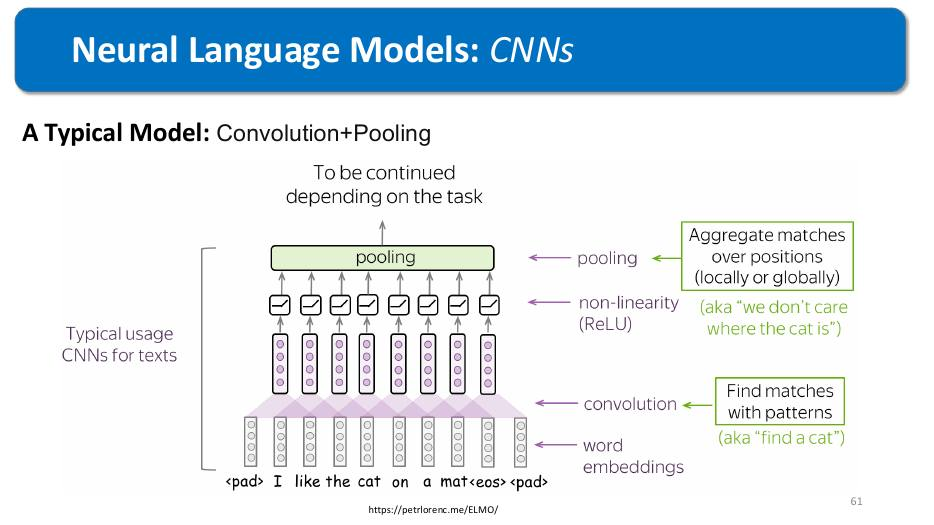
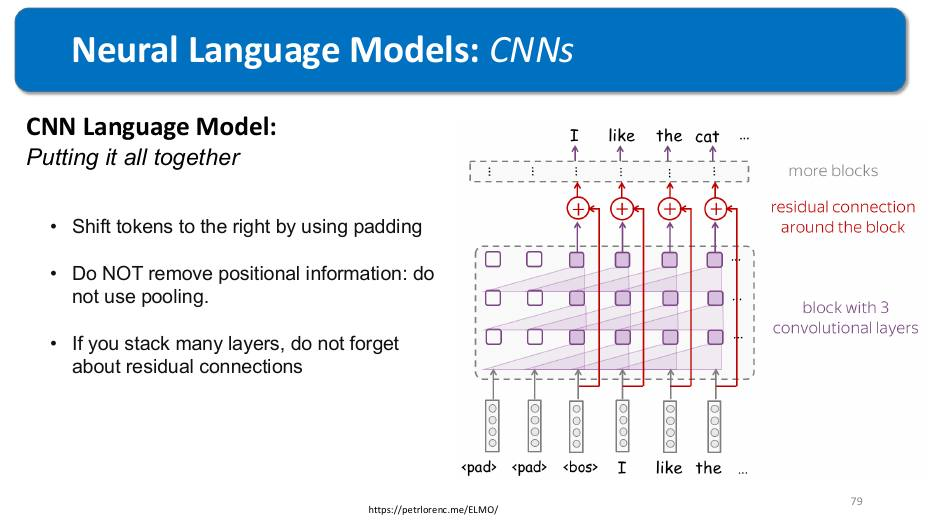

In [ ]:
class CNNLM(nn.Module):
    def __init__(self, vocab_size, dim=256, kernel_size=3, layers=4):
        super().__init__()
        self.k = kernel_size
        self.embed = nn.Embedding(vocab_size, dim)
        self.convs = nn.ModuleList([nn.Conv1d(dim, dim, kernel_size) for _ in range(layers)])
        self.out = nn.Linear(dim, vocab_size)

    def forward(self, x):
        h = self.embed(x).transpose(1, 2)        # Conv1d wants (batch, channels, seq)
        for conv in self.convs:
            padded = F.pad(h, (self.k - 1, 0))   # left padding only -> causal
            h = h + F.relu(conv(padded))         # residual connection
        return self.out(h.transpose(1, 2))       # back to (batch, seq, vocab)

cnn = train_lm(CNNLM(V))
results["CNN"] = perplexity(cnn)
print(generate(cnn, "the history of the"))

## 3. Transformer (encoder-decoder)
The original Transformer has an **encoder** that reads the whole input with self-attention, and a **decoder** that generates the output one token at a time while attending to the encoder. This is the architecture of **T5 / BART** (text in → text out).

| Architecture | Models | Use |
|---|---|---|
| Encoder + decoder | T5, BART | translation, summarization |
| Encoder only | BERT | understanding (classification, NER, QA) |
| Decoder only | GPT | generation |

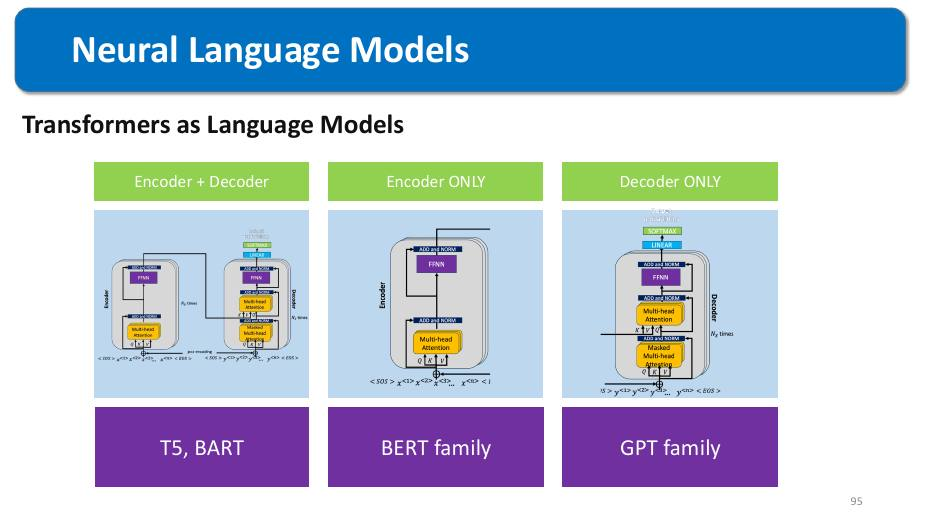

To see it learn quickly we use a toy "translation" task: **the output is the input sequence reversed** (e.g. `3 1 4 1 5` → `5 1 4 1 3`). The decoder gets the target shifted right with a start token (`BOS`), plus a **causal mask** so it can't peek ahead.

In [ ]:
BOS, VOCAB_DIGITS = 10, 11          # tokens 0-9 are digits, 10 is the start token

def make_pairs(n, length=8):
    src = torch.randint(0, 10, (n, length))
    tgt = torch.flip(src, dims=[1])                                       # the answer: reversed
    tgt_in = torch.cat([torch.full((n, 1), BOS), tgt[:, :-1]], dim=1)     # decoder input, shifted right
    return src.to(device), tgt_in.to(device), tgt.to(device)

class Seq2SeqTransformer(nn.Module):
    def __init__(self, vocab_size=VOCAB_DIGITS, dim=64):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, dim)
        self.pos = nn.Embedding(32, dim)                                   # learned position embeddings
        self.transformer = nn.Transformer(dim, nhead=4, num_encoder_layers=2, num_decoder_layers=2,
                                          dim_feedforward=128, batch_first=True)
        self.out = nn.Linear(dim, vocab_size)

    def emb(self, x):
        return self.embed(x) + self.pos(torch.arange(x.size(1), device=x.device))

    def forward(self, src, tgt_in):
        causal = nn.Transformer.generate_square_subsequent_mask(tgt_in.size(1)).to(src.device)
        h = self.transformer(self.emb(src), self.emb(tgt_in), tgt_mask=causal)
        return self.out(h)

seq2seq = Seq2SeqTransformer().to(device)
opt = torch.optim.AdamW(seq2seq.parameters(), lr=1e-3)
for step in range(1501):
    src, tgt_in, tgt = make_pairs(64)
    loss = F.cross_entropy(seq2seq(src, tgt_in).reshape(-1, VOCAB_DIGITS), tgt.reshape(-1))
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 300 == 0:
        print(f"step {step:4d} | loss {loss.item():.3f}")

In [ ]:
@torch.no_grad()
def translate(src):
    seq2seq.eval()
    out = torch.full((1, 1), BOS, device=device)
    for _ in range(src.size(1)):                               # generate one token at a time
        next_tok = seq2seq(src, out)[:, -1].argmax(-1, keepdim=True)
        out = torch.cat([out, next_tok], dim=1)
    return out[0, 1:].tolist()

src, _, tgt = make_pairs(1)
print("input   :", src[0].tolist())
print("output  :", translate(src))
print("correct :", tgt[0].tolist())

## 4. GPT (decoder-only Transformer), from scratch
GPT keeps only the decoder side: token embeddings + position embeddings → a stack of **masked self-attention** blocks → a linear layer to vocabulary scores (the **logits**) → softmax. The **causal mask** means each word only attends to itself and the words before it, so it can be trained on next-word prediction and then generate text left to right.

(PyTorch calls the block `TransformerEncoderLayer`; with a causal mask and no cross-attention it's exactly a GPT block.)

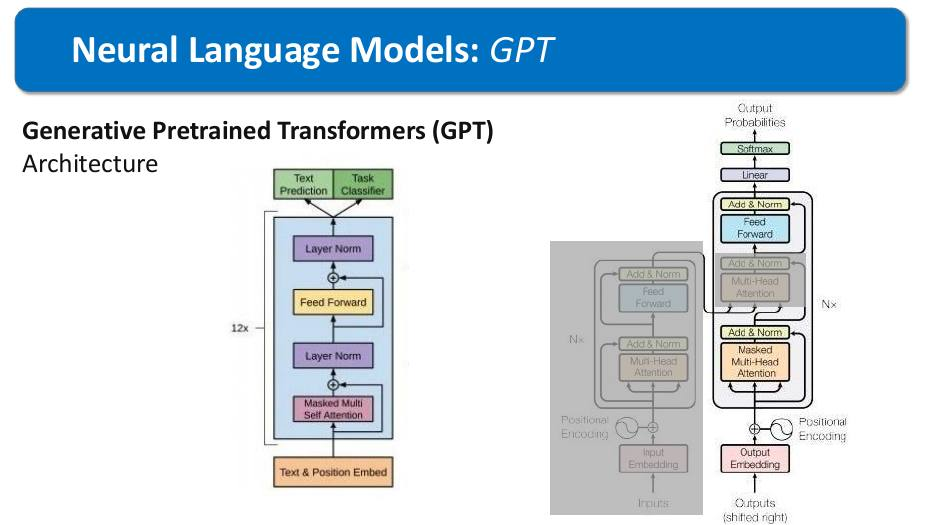
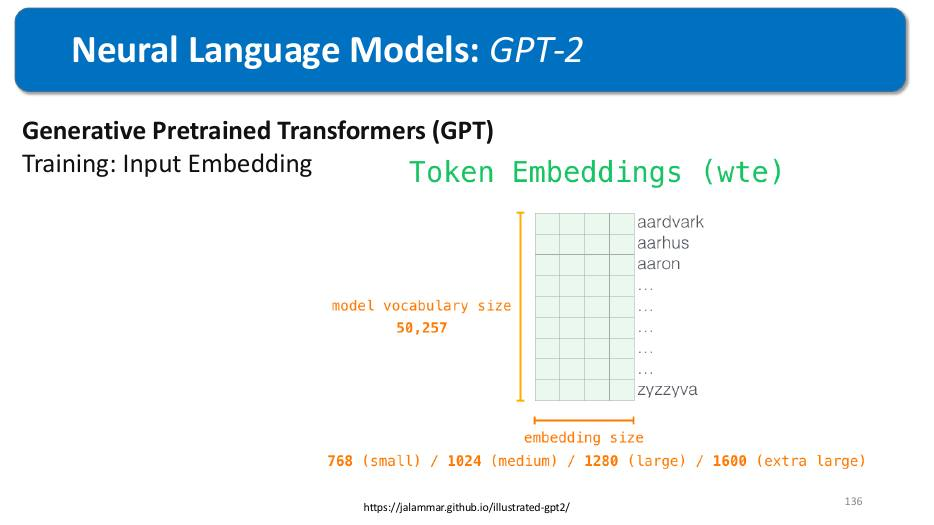

In [ ]:
class MiniGPT(nn.Module):
    def __init__(self, vocab_size, dim=256, heads=4, layers=4, max_len=SEQ_LEN):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab_size, dim)
        self.pos_emb = nn.Embedding(max_len, dim)
        block = nn.TransformerEncoderLayer(dim, heads, dim_feedforward=4 * dim, dropout=0.1,
                                           batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(block, layers)
        self.norm = nn.LayerNorm(dim)
        self.out = nn.Linear(dim, vocab_size)

    def forward(self, x):
        T = x.size(1)
        h = self.tok_emb(x) + self.pos_emb(torch.arange(T, device=x.device))
        causal = nn.Transformer.generate_square_subsequent_mask(T).to(x.device)   # word t sees only <= t
        h = self.blocks(h, mask=causal, is_causal=True)
        return self.out(self.norm(h))                                              # logits

gpt = train_lm(MiniGPT(V), lr=1e-3)
results["Mini GPT (Transformer)"] = perplexity(gpt)
print(generate(gpt, "the history of the"))

## 5. BERT (encoder-only Transformer), from scratch
BERT uses the same blocks **without** the causal mask, so every word sees the whole sentence (left and right). That means it can't be trained on "predict the next word" (it would just look). Instead it's trained by **masked word prediction**: hide ~15% of the words with `[MASK]` and predict them. (The original BERT also used next-sentence prediction, with `[CLS]` and `[SEP]` tokens.)

BERT is for **understanding** (classification, NER, QA) rather than generation.

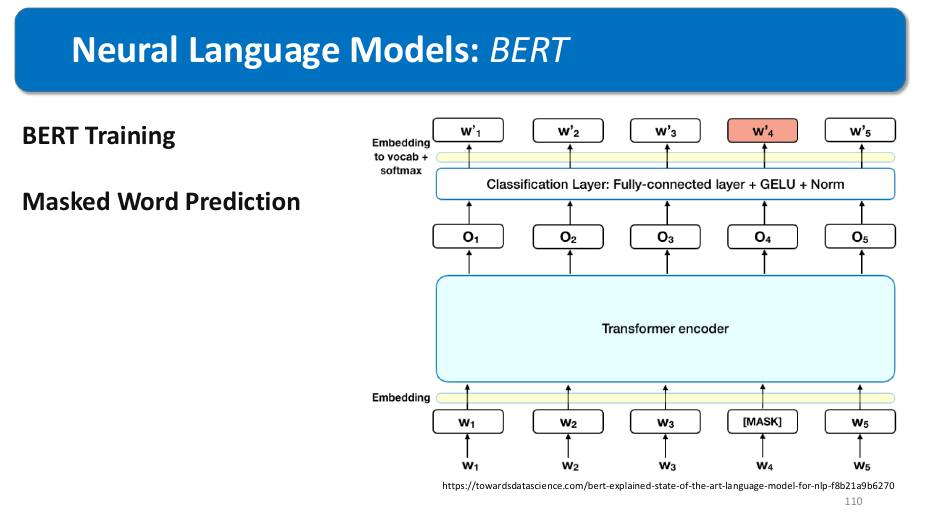
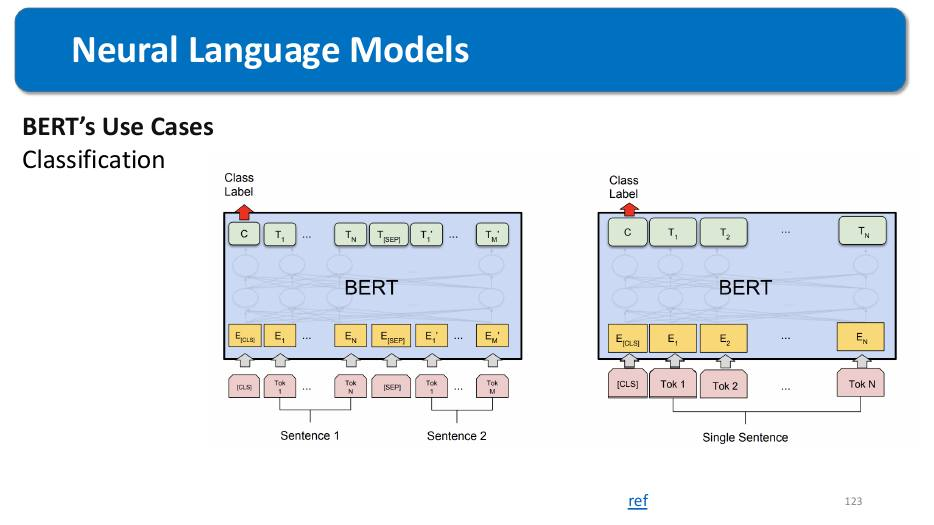

In [ ]:
MASK_ID = stoi["<mask>"]

def mask_tokens(x, prob=0.15):
    labels = x.clone()
    chosen = torch.rand(x.shape, device=x.device) < prob
    labels[~chosen] = -100                 # -100 = ignore in the loss: only score the masked words
    x = x.clone()
    x[chosen] = MASK_ID
    return x, labels

class MiniBERT(MiniGPT):
    def forward(self, x):                  # same as MiniGPT but with NO causal mask
        h = self.tok_emb(x) + self.pos_emb(torch.arange(x.size(1), device=x.device))
        return self.out(self.norm(self.blocks(h)))

bert = MiniBERT(V).to(device)
opt = torch.optim.AdamW(bert.parameters(), lr=1e-3)
for step in range(1501):
    x, _ = get_batch(train_ids)
    x_masked, labels = mask_tokens(x)
    logits = bert(x_masked)
    loss = F.cross_entropy(logits.reshape(-1, V), labels.reshape(-1), ignore_index=-100)
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 300 == 0:
        print(f"step {step:4d} | masked-word loss {loss.item():.2f}")

In [ ]:
@torch.no_grad()
def fill_mask(sentence, top_k=5):
    # write the hidden word as "_" , e.g. "the _ of the united states"
    tokens = tokenize(sentence)
    ids = torch.tensor([[MASK_ID if t == "_" else stoi.get(t, 0) for t in tokens]], device=device)
    pos = tokens.index("_")
    bert.eval()
    probs = F.softmax(bert(ids)[0, pos], dim=-1)
    bert.train()
    top = probs.topk(top_k)
    return [(itos[i], round(p, 3)) for p, i in zip(top.values.tolist(), top.indices.tolist())]

print(fill_mask("the _ of the united states"))
print(fill_mask("he was born in _ ."))

## 6. The real pre-trained models (Hugging Face)
Same ideas, but trained on far more data. **Logits** = the raw scores of the last layer before softmax.

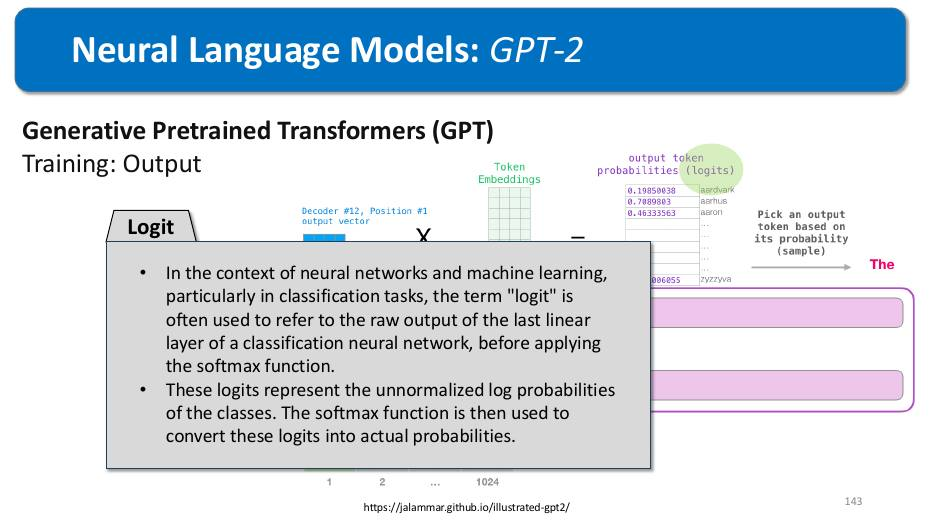

In [ ]:
from transformers import AutoTokenizer, AutoModelForMaskedLM

# BERT: see the special tokens and fill a mask
bert_tok = AutoTokenizer.from_pretrained("bert-base-uncased")
bert_mlm = AutoModelForMaskedLM.from_pretrained("bert-base-uncased").to(device).eval()

enc = bert_tok("The patient has a [MASK] in the left lung.", return_tensors="pt").to(device)
print(bert_tok.convert_ids_to_tokens(enc["input_ids"][0]))       # [CLS] ... [SEP]  (ids 101 / 102)

with torch.no_grad():
    logits = bert_mlm(**enc).logits
mask_pos = (enc["input_ids"][0] == bert_tok.mask_token_id).nonzero()[0, 0]
print(bert_tok.convert_ids_to_tokens(logits[0, mask_pos].topk(5).indices))

In [ ]:
from transformers import AutoModelForCausalLM

# GPT-2: next-word logits, generation, and perplexity on our validation text
gpt_tok = AutoTokenizer.from_pretrained("gpt2")
gpt2 = AutoModelForCausalLM.from_pretrained("gpt2").to(device).eval()

ids = gpt_tok("The history of the", return_tensors="pt").input_ids.to(device)
with torch.no_grad():
    next_logits = gpt2(ids).logits[0, -1]
print("top next tokens:", [gpt_tok.decode(i) for i in next_logits.topk(5).indices])

out = gpt2.generate(ids, max_new_tokens=20, do_sample=True, top_k=50, pad_token_id=gpt_tok.eos_token_id)
print(gpt_tok.decode(out[0]))

# perplexity = exp(average loss); passing labels=input makes the model compute next-token loss
chunk = gpt_tok(val_text[:5000], return_tensors="pt").input_ids[:, :512].to(device)
with torch.no_grad():
    loss = gpt2(chunk, labels=chunk).loss
print("GPT-2 perplexity on WikiText-2 sample:", round(math.exp(loss.item()), 1))

In [ ]:
# Fine-tuning GPT-2 for a few steps on our training text (same loss as before)
opt = torch.optim.AdamW(gpt2.parameters(), lr=5e-5)
gpt2.train()
train_chunk = gpt_tok(train_text[:200_000], return_tensors="pt").input_ids[0]
for step in range(50):
    start = random.randint(0, len(train_chunk) - 129)
    batch = train_chunk[start : start + 128].unsqueeze(0).to(device)
    loss = gpt2(batch, labels=batch).loss
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 10 == 0:
        print(f"step {step} | loss {loss.item():.2f}")
gpt2.eval()

In [ ]:
# T5: encoder-decoder, every task is "text in -> text out" with a task prefix
from transformers import AutoModelForSeq2SeqLM

t5_tok = AutoTokenizer.from_pretrained("t5-small")
t5 = AutoModelForSeq2SeqLM.from_pretrained("t5-small").to(device)

for prompt in ["translate English to French: The patient has a fever.",
               "summarize: The patient was admitted with chest pain. A CT scan showed no abnormality. "
               "She was discharged the next day and asked to follow up with cardiology."]:
    ids = t5_tok(prompt, return_tensors="pt").input_ids.to(device)
    print(t5_tok.decode(t5.generate(ids, max_new_tokens=40)[0], skip_special_tokens=True))

## 7. Compare: perplexity
Lower is better. The worst possible is |V| (random guessing). GPT-2's number uses its own tokenizer, so it isn't directly comparable, but it shows what lots of data and parameters buy you.

Other metrics from the lecture: **cross entropy** (perplexity is just exp of it) and **BLEU** for translation (n-gram overlap with clipping and a brevity penalty).

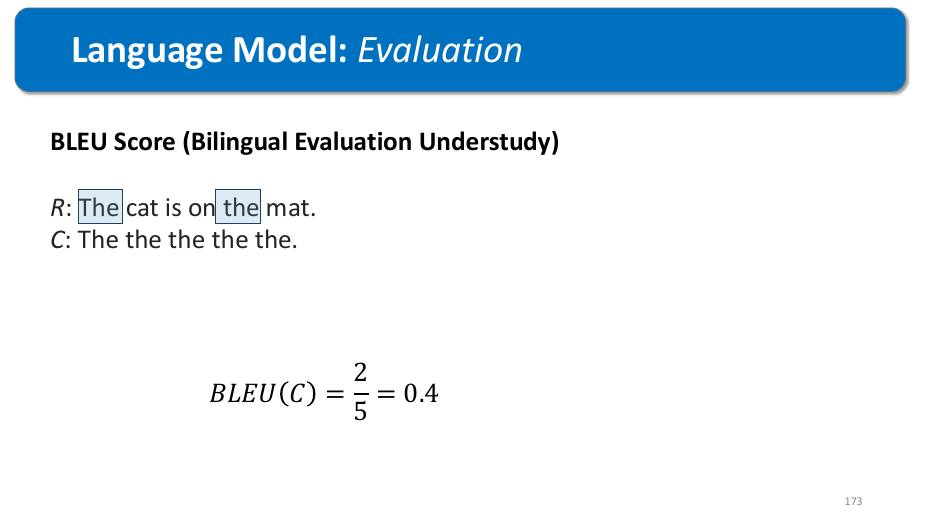

In [ ]:
print(f"{'uniform guessing':25} {V:8.1f}")
for name, ppl in results.items():
    print(f"{name:25} {ppl:8.1f}")

In [ ]:
# BLEU for the T5 translation (pip install nltk)
from nltk.translate.bleu_score import sentence_bleu
reference = ["le patient a de la fièvre .".split()]
candidate = "le patient a une fièvre .".split()
print("BLEU-2:", round(sentence_bleu(reference, candidate, weights=(0.5, 0.5)), 3))

## Using a pre-trained LM for your own task
Train from scratch · **fine-tune** (full, last layers only, adapters, or a new task head, like the GPT-2 cell above) · use its embeddings as **features** · **prompt** it.

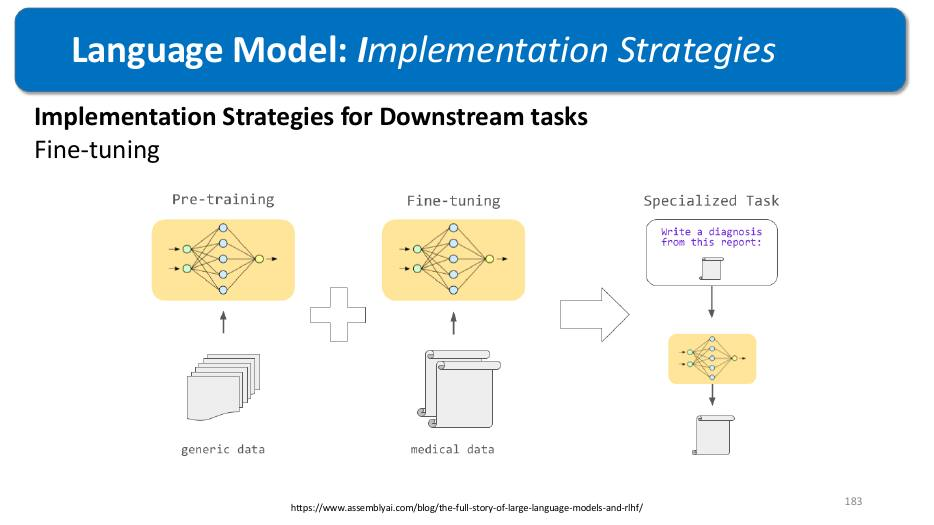